In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error

SEED = 42
rng = np.random.default_rng(SEED)

print("Random seed:", SEED)
print("Noise standard deviation:", 0.3)
print("Noise variance / approximate noise floor:", 0.3**2)


Random seed: 42
Noise standard deviation: 0.3
Noise variance / approximate noise floor: 0.09


In [2]:
# defining given true function 

f = lambda x: np.sin(2 * np.pi * x)

def make_wave_data(n):
    x = rng.uniform(0, 1, n)
    y = f(x) + rng.normal(0, 0.3, n)
    return x.reshape(-1, 1), y

def poly(degree):
    return make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )


In [3]:
# One training set (n=30) and one fixed test set (n=1000)
# one dataset fed to 12 different models differing in complexities (degree 1 to 12) and then train, test errors are compared

X_train, y_train = make_wave_data(30)
X_test, y_test = make_wave_data(1000)

single_results = []

for degree in range(1, 13):
    model = poly(degree)
    model.fit(X_train, y_train)

    train_mse = mean_squared_error(y_train, model.predict(X_train))
    test_mse = mean_squared_error(y_test, model.predict(X_test))

    single_results.append([degree, train_mse, test_mse])

single_df = pd.DataFrame(
    single_results,
    columns=["Degree", "Training MSE", "Test MSE"]
)

single_df.round(4)


,Degree,Training MSE,Test MSE
0,1,0.2062,0.2935
1,2,0.2019,0.2955
2,3,0.0638,0.1024
3,4,0.0611,0.1105
4,5,0.0473,0.1218
5,6,0.0448,0.1435
6,7,0.0447,0.1399
7,8,0.0446,0.1297
8,9,0.0438,0.1134
9,10,0.0436,0.1114


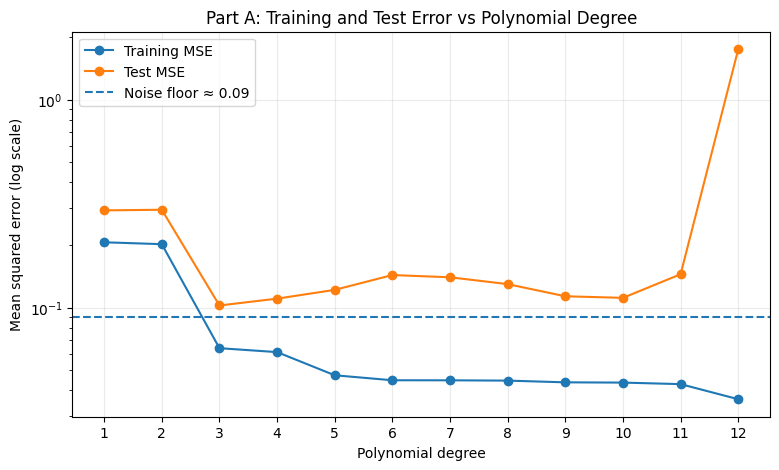

In [ ]:
# Plotting: one training set
# overfitting 

plt.figure(figsize=(9, 5))
plt.plot(single_df["Degree"], single_df["Training MSE"], marker="o", label="Training MSE")
plt.plot(single_df["Degree"], single_df["Test MSE"], marker="o", label="Test MSE")
plt.axhline(0.09, linestyle="--", label="Noise floor ≈ 0.09")

plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error (log scale)")
plt.title("Part A: Training and Test Error vs Polynomial Degree")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()


In [ ]:
# now 50 different training datasets and on each of those 50 datasets, 12 models are applied. (on 1st dataset 12, on second 
# dataset 12 models like that for all 50) testing dataset remains same for all of those 50 training datasets so that we can compare the results. 
# 50 datasets -> 12 models on each ->  average the errors
# hence we simply loop the above function 50 times for 50 random datasets. 

repeated_results = []

for repeat in range(50):
    X, y = make_wave_data(30)

    for degree in range(1, 13):
        model = poly(degree)
        model.fit(X, y)

        train_mse = mean_squared_error(y, model.predict(X))
        test_mse = mean_squared_error(y_test, model.predict(X_test))

        repeated_results.append([repeat + 1, degree, train_mse, test_mse])

repeated_df = pd.DataFrame(
    repeated_results,
    columns=["Repeat", "Degree", "Training MSE", "Test MSE"]
)

average_curve = (
    repeated_df.groupby("Degree")[["Training MSE", "Test MSE"]]
    .mean()
    .reset_index()
)

average_curve.round(4)


,Degree,Training MSE,Test MSE
0,1,0.2574,0.3218
1,2,0.2431,0.3507
2,3,0.0788,0.1177
3,4,0.0753,0.1276
4,5,0.0712,0.1384
5,6,0.0680,0.2102
6,7,0.0659,0.4674
7,8,0.0634,4.1368
8,9,0.0596,3.9013
9,10,0.0567,135.5716


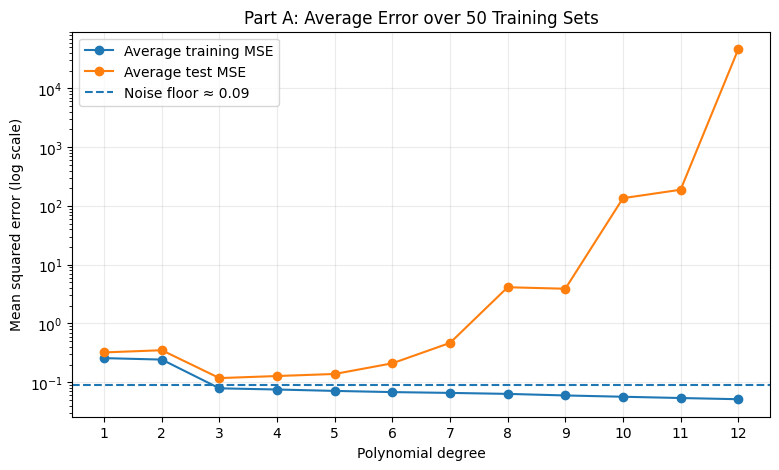

In [6]:
# Plot the averaged curves from the 50 repeated training sets

plt.figure(figsize=(9, 5))
plt.plot(average_curve["Degree"], average_curve["Training MSE"],
         marker="o", label="Average training MSE")
plt.plot(average_curve["Degree"], average_curve["Test MSE"],
         marker="o", label="Average test MSE")
plt.axhline(0.09, linestyle="--", label="Noise floor ≈ 0.09")

plt.yscale("log")
plt.xlabel("Polynomial degree")
plt.ylabel("Mean squared error (log scale)")
plt.title("Part A: Average Error over 50 Training Sets")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True, alpha=0.25)
plt.show()
